In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import scanpy.external as sce
import sys

sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
#sc.logging.print_versions()

#sc.settings.set_figure_params(dpi=80)
%matplotlib inline 
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower
sc.set_figure_params(scanpy=True, fontsize=14 )
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = ['sans-serif']
plt.rcParams['font.sans-serif'] = ['Arial']

In [2]:
import loompy as lp
import pandas as pd

In [3]:
lf = lp.connect("All_pyscenic_output.loom",  validate=False , mode='r+')

In [4]:
lf

,,CellID,AAAGTCCGTCGTGTTA-1-adata1,AAAGTGACATCTCGTC-1-adata1,AACAGGGAGACTCTTG-1-adata1,AACCTTTCACGTCGGT-1-adata1,AACGAAAAGAATGTTG-1-adata1,AACGTCAGTGGTTTGT-1-adata1,AAGACAATCCACGGAC-1-adata1,AAGCGAGCACCACTGG-1-adata1,AAGTACCCACCTTCGT-1-adata1,AATGAAGAGCCATGCC-1-adata1,...
,,RegulonsAUC,"(0.02613496, 0.03684772, 0.0339454, 0., 0.04836879, 0., 0.04810231, 0.01596326, 0.04878775, 0.08171084, 0., 0.10691773, 0.08045395, 0.10412771, 0.02538598, 0.07446809, 0.09886411, 0.05974963, 0.03395081, 0.02359307, 0., 0., 0.08991849, 0.04085347, 0.04938759, 0.08885662, 0.16883519, 0.06083589, 0.05203246, 0., 0.15241636, 0., 0.07757614, 0.09350256, 0.06175134, 0.077985, 0.05483271, 0.07618681, 0., 0.07378843, 0.0831978, 0., 0.41500507, 0.05556275, 0.12246293, 0.01843716, 0.05415309, 0.05601787, 0.03880816, 0.03100511, 0.04950821, 0.02968954, 0.06480098, 0., 0.00313787, 0.06282823, 0.03552112, 0.07304763, 0.07640231, 0.00210657, 0.00432116, 0., 0., 0.03082689, 0.0249771, 0.0576948, 0., 0., 0.04404541, 0.02664188, 0., 0.01169765, 0.00268484, 0.07477971, 0.02890737, 0.04511659, 0., 0.09041045, 0.1302437, 0.05530906, 0.01665933, 0.07103973, 0.03122677, 0.05293426, 0., 0., 0.05542846, 0.00508055, 0., 0.0185274, 0.01148286, 0.01029681, 0.0273303, 0., 0.00478526, 0.04016535, 0.0296107, 0.03279178, 0.10567937, 0.05124568, 0.06119251, 0.02178308, 0., 0.05513352, 0.04208369, 0., 0.03103889, 0., 0.01492797, 0.01040892, 0.05887672, 0.06612281, 0., 0.11194719, 0.09481901, 0.07916309, 0.06259958, 0., 0., 0.05992245, 0.03371601, 0.06009455, 0.10006196, 0.05449878, 0.03608078, 0.0767755, 0.0444762, 0.06135555, 0.07554486, 0., 0.03601442, 0.06532846, 0.02248292, 0.02324895, 0.09820251, 0.04776952, 0., 0.05129226, 0.10276751, 0.04051356, 0.02528281, 0.02623427, 0.05771995, 0.03078532, 0.01025747, 0.03486908, 0.02705494, 0.03581866, 0.06653973, 0.07675645, 0.04001135, 0., 0.01018432, 0., 0.02413096, 0.10318838, 0.01205884, 0.01692849, 0.05233809, 0.11592852, 0., 0.05591198, 0.05418497, 0.05266419, 0.07865388, 0.04129049, 0.09460967, 0.01545074, 0.10669967, 0.40535936, 0., 0.08359887, 0., 0.01486989, 0.02687423, 0.02903759, 0.02426792, 0.02465923, 0., 0., 0.00247831, 0.03789756, 0.10074349, 0.05873241, 0., 0.00075726, 0.09154662, 0.0354399, 0.07831976, 0.08681118, 0., 0.06417354, 0.02938573, 0.03903346, 0.02089529, 0.03845661, 0.00254716, 0.01391839, 0.04257391, 0.07427795, 0., 0., 0.08887337, 0.07022202, 0.03508186, 0., 0.05255644, 0., 0.00444031, 0., 0.01288296, 0.07161329, 0.04572491, 0.01722523, 0.06375089, 0., 0.02675769, 0.06573167, 0.03433583, 0.10625774, 0.05340424, 0.05667323, 0.03482032, 0., 0.0712745, 0.06907777, 0.03754579, 0.02256419, 0.03010306, 0.10111524, 0.08249831, 0.09019295, 0.08769085, 0.02345105, 0., 0.06915678, 0.05274233, 0.03412679, 0.04920004, 0., 0.0108561, 0.18113825, 0.11203692, 0.06361867, 0.09238959, 0.07077654, 0.11545044, 0.02786663, 0., 0., 0.04287652, 0.14776952, 0.06810733, 0.04170129, 0.09599133, 0., 0.07715664, 0.08568638, 0.05395999, 0.07261692, 0.06354657, 0.03232135, 0.02254728, 0.09289358, 0., 0.05873481, 0.0234859, 0.07609553, 0.04668968, 0.00552233, 0.03522747, 0.05413052, 0.10411788, 0.09223608, 0.01831199, 0.09701922, 0.11666011, 0.11388348, 0.04718092, 0.01114357, 0.04875608, 0.06913662, 0.00834218, 0.03159851, 0., 0.05333156, 0., 0.02604542, 0.09149112, 0.04207972, 0., 0.01416386, 0.09222939, 0., 0.06922384, 0.06110178, 0.05935564, 0.01253736, 0.08112301, 0.04344183, 0.14108692, 0.01355328, 0.07982919, 0.09431833, 0.15747625, 0., 0., 0.07269078, 0.02165264, 0.03589801, 0.10672095, 0.06198554, 0.0008261, 0., 0.0887518, 0.03511166, 0., 0.03929899, 0.0861418, 0., 0.03855156, 0., 0., 0.03787511, 0.03224287, 0.07723807, 0.00482386, 0.09823764, 0.09743509, 0.08828557, 0.05489843, 0.14588262, 0., 0.03077241, 0., 0., 0.03571613, 0.10260223, 0.00690388, 0., 0.04292795, 0.06340627, 0.01450847, 0.00875155, 0.13161622, 0.06996473, 0.05803387, 0.05895716, 0.1425031, 0., 0.04549096, 0.06453945, 0.0371184, 0.04680635, 0.13840699, 

In [5]:
lf.ca.CellID

array(['AAAGTCCGTCGTGTTA-1-adata1', 'AAAGTGACATCTCGTC-1-adata1',
       'AACAGGGAGACTCTTG-1-adata1', ..., 'TTGTTCACACTAGAGG-1-adata12',
       'TTGTTTGAGTGCCGAA-1-adata12', 'TTTGGAGAGTCAATCC-1-adata12'],
      dtype=object)

In [6]:
lf.ca.RegulonsAUC

array([(0.02613496, 0.03684772, 0.0339454 , 0., 0.04836879, 0.        , 0.04810231, 0.01596326, 0.04878775, 0.08171084, 0.        , 0.10691773, 0.08045395, 0.10412771, 0.02538598, 0.07446809, 0.09886411, 0.05974963, 0.03395081, 0.02359307, 0., 0.        , 0.08991849, 0.04085347, 0.04938759, 0.08885662, 0.16883519, 0.06083589, 0.05203246, 0.        , 0.15241636, 0., 0.07757614, 0.09350256, 0.06175134, 0.077985  , 0.05483271, 0.07618681, 0.        , 0.07378843, 0.0831978 , 0., 0.41500507, 0.05556275, 0.12246293, 0.01843716, 0.05415309, 0.05601787, 0.03880816, 0.03100511, 0.04950821, 0.02968954, 0.06480098, 0.        , 0.00313787, 0.06282823, 0.03552112, 0.07304763, 0.07640231, 0.00210657, 0.00432116, 0.        , 0., 0.03082689, 0.0249771 , 0.0576948 , 0., 0., 0.04404541, 0.02664188, 0.        , 0.01169765, 0.00268484, 0.07477971, 0.02890737, 0.04511659, 0.        , 0.09041045, 0.1302437 , 0.05530906, 0.01665933, 0.07103973, 0.03122677, 0.05293426, 0.        , 0., 0.05542846, 0.00508055, 

In [7]:
auc_mtx = pd.DataFrame( lf.ca.RegulonsAUC, index=lf.ca.CellID)

In [8]:
auc_mtx

,Ahdc1(+),Ak6(+),Arid3a(+),Arntl(+),Ascc1(+),Atf2(+),Atf4(+),Atf5(+),Bach1(+),Bach2(+),...,Zfp882(+),Zfp91(+),Zfp941(+),Zfx(+),Zic1(+),Zic4(+),Zkscan6(+),Zkscan8(+),Zxdb(+),Zxdc(+)
AAAGTCCGTCGTGTTA-1-adata1,0.026135,0.036848,0.033945,0.0,0.048369,0.000000,0.048102,0.015963,0.048788,0.081711,...,0.060497,0.042640,0.037553,0.071960,0.034723,0.000000,0.000000,0.000000,0.000000,0.000000
AAAGTGACATCTCGTC-1-adata1,0.015371,0.029287,0.036621,0.0,0.038575,0.045023,0.050505,0.014153,0.031077,0.086664,...,0.014162,0.025764,0.047628,0.075007,0.053025,0.000487,0.000000,0.056629,0.000000,0.015541
AACAGGGAGACTCTTG-1-adata1,0.005032,0.057454,0.014288,0.0,0.022904,0.000000,0.031601,0.005631,0.018363,0.050153,...,0.000000,0.041460,0.030307,0.036058,0.026629,0.008895,0.000000,0.007435,0.000000,0.000000
AACCTTTCACGTCGGT-1-adata1,0.016203,0.017583,0.036095,0.0,0.033348,0.000000,0.036644,0.003790,0.012848,0.079215,...,0.014560,0.015423,0.027108,0.057198,0.059159,0.000000,0.015489,0.000000,0.000000,0.000000
AACGAAAAGAATGTTG-1-adata1,0.039140,0.027313,0.064915,0.0,0.048541,0.000000,0.076117,0.027176,0.072222,0.115094,...,0.000000,0.021538,0.079403,0.112491,0.064252,0.000000,0.000000,0.000000,0.058447,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGGATGTCATGGCCG-1-adata12,0.030234,0.033354,0.048496,0.0,0.035170,0.013355,0.042126,0.032953,0.053895,0.088369,...,0.005089,0.032351,0.105491,0.069166,0.066172,0.000000,0.077034,0.027096,0.009156,0.034903
TTGGGCGCATGGACAG-1-adata12,0.041355,0.017423,0.033176,0.0,0.033400,0.000000,0.032767,0.017773,0.091535,0.102833,...,0.005045,0.034165,0.153699,0.064717,0.070566,0.053284,0.072078,0.000000,0.009500,0.000000
TTGTTCACACTAGAGG-1-adata12,0.015083,0.025294,0.033382,0.0,0.016885,0.026435,0.034377,0.022566,0.027934,0.080700,...,0.000000,0.028043,0.054026,0.048105,0.043476,0.001992,0.000000,0.035564,0.000000,0.010120
TTGTTTGAGTGCCGAA-1-adata12,0.031148,0.044455,0.051622,0.0,0.027137,0.071802,0.052879,0.049226,0.051527,0.071042,...,0.000000,0.052576,0.102920,0.048483,0.031528,0.000000,0.000000,0.025609,0.062509,0.000000


In [9]:
auc_mtx = pd.DataFrame( lf.ca.RegulonsAUC, index=lf.ca.CellID)
regulons = lf.ra.Regulons

In [10]:
auc_mtx

,Ahdc1(+),Ak6(+),Arid3a(+),Arntl(+),Ascc1(+),Atf2(+),Atf4(+),Atf5(+),Bach1(+),Bach2(+),...,Zfp882(+),Zfp91(+),Zfp941(+),Zfx(+),Zic1(+),Zic4(+),Zkscan6(+),Zkscan8(+),Zxdb(+),Zxdc(+)
AAAGTCCGTCGTGTTA-1-adata1,0.026135,0.036848,0.033945,0.0,0.048369,0.000000,0.048102,0.015963,0.048788,0.081711,...,0.060497,0.042640,0.037553,0.071960,0.034723,0.000000,0.000000,0.000000,0.000000,0.000000
AAAGTGACATCTCGTC-1-adata1,0.015371,0.029287,0.036621,0.0,0.038575,0.045023,0.050505,0.014153,0.031077,0.086664,...,0.014162,0.025764,0.047628,0.075007,0.053025,0.000487,0.000000,0.056629,0.000000,0.015541
AACAGGGAGACTCTTG-1-adata1,0.005032,0.057454,0.014288,0.0,0.022904,0.000000,0.031601,0.005631,0.018363,0.050153,...,0.000000,0.041460,0.030307,0.036058,0.026629,0.008895,0.000000,0.007435,0.000000,0.000000
AACCTTTCACGTCGGT-1-adata1,0.016203,0.017583,0.036095,0.0,0.033348,0.000000,0.036644,0.003790,0.012848,0.079215,...,0.014560,0.015423,0.027108,0.057198,0.059159,0.000000,0.015489,0.000000,0.000000,0.000000
AACGAAAAGAATGTTG-1-adata1,0.039140,0.027313,0.064915,0.0,0.048541,0.000000,0.076117,0.027176,0.072222,0.115094,...,0.000000,0.021538,0.079403,0.112491,0.064252,0.000000,0.000000,0.000000,0.058447,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGGATGTCATGGCCG-1-adata12,0.030234,0.033354,0.048496,0.0,0.035170,0.013355,0.042126,0.032953,0.053895,0.088369,...,0.005089,0.032351,0.105491,0.069166,0.066172,0.000000,0.077034,0.027096,0.009156,0.034903
TTGGGCGCATGGACAG-1-adata12,0.041355,0.017423,0.033176,0.0,0.033400,0.000000,0.032767,0.017773,0.091535,0.102833,...,0.005045,0.034165,0.153699,0.064717,0.070566,0.053284,0.072078,0.000000,0.009500,0.000000
TTGTTCACACTAGAGG-1-adata12,0.015083,0.025294,0.033382,0.0,0.016885,0.026435,0.034377,0.022566,0.027934,0.080700,...,0.000000,0.028043,0.054026,0.048105,0.043476,0.001992,0.000000,0.035564,0.000000,0.010120
TTGTTTGAGTGCCGAA-1-adata12,0.031148,0.044455,0.051622,0.0,0.027137,0.071802,0.052879,0.049226,0.051527,0.071042,...,0.000000,0.052576,0.102920,0.048483,0.031528,0.000000,0.000000,0.025609,0.062509,0.000000


In [11]:
res=pd.concat([pd.Series(r.tolist(),index=regulons.dtype.names) for r in regulons],axis=1)

In [12]:
res.to_csv("epcam_placods_7_16_06.csv")


In [13]:
res

,0,1,2,3,4,5,6,7,8,9,...,32275,32276,32277,32278,32279,32280,32281,32282,32283,32284
Ahdc1(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Ak6(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Arid3a(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Arntl(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Ascc1(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zic4(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zkscan6(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zkscan8(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zxdb(+),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [16]:
adata_genes=sc.read_h5ad('sub_OTIC.h5ad')

In [17]:
adata_genes

AnnData object with n_obs × n_vars = 7153 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'lognorm'
    obsp: 'connectivities', 'distances'

/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


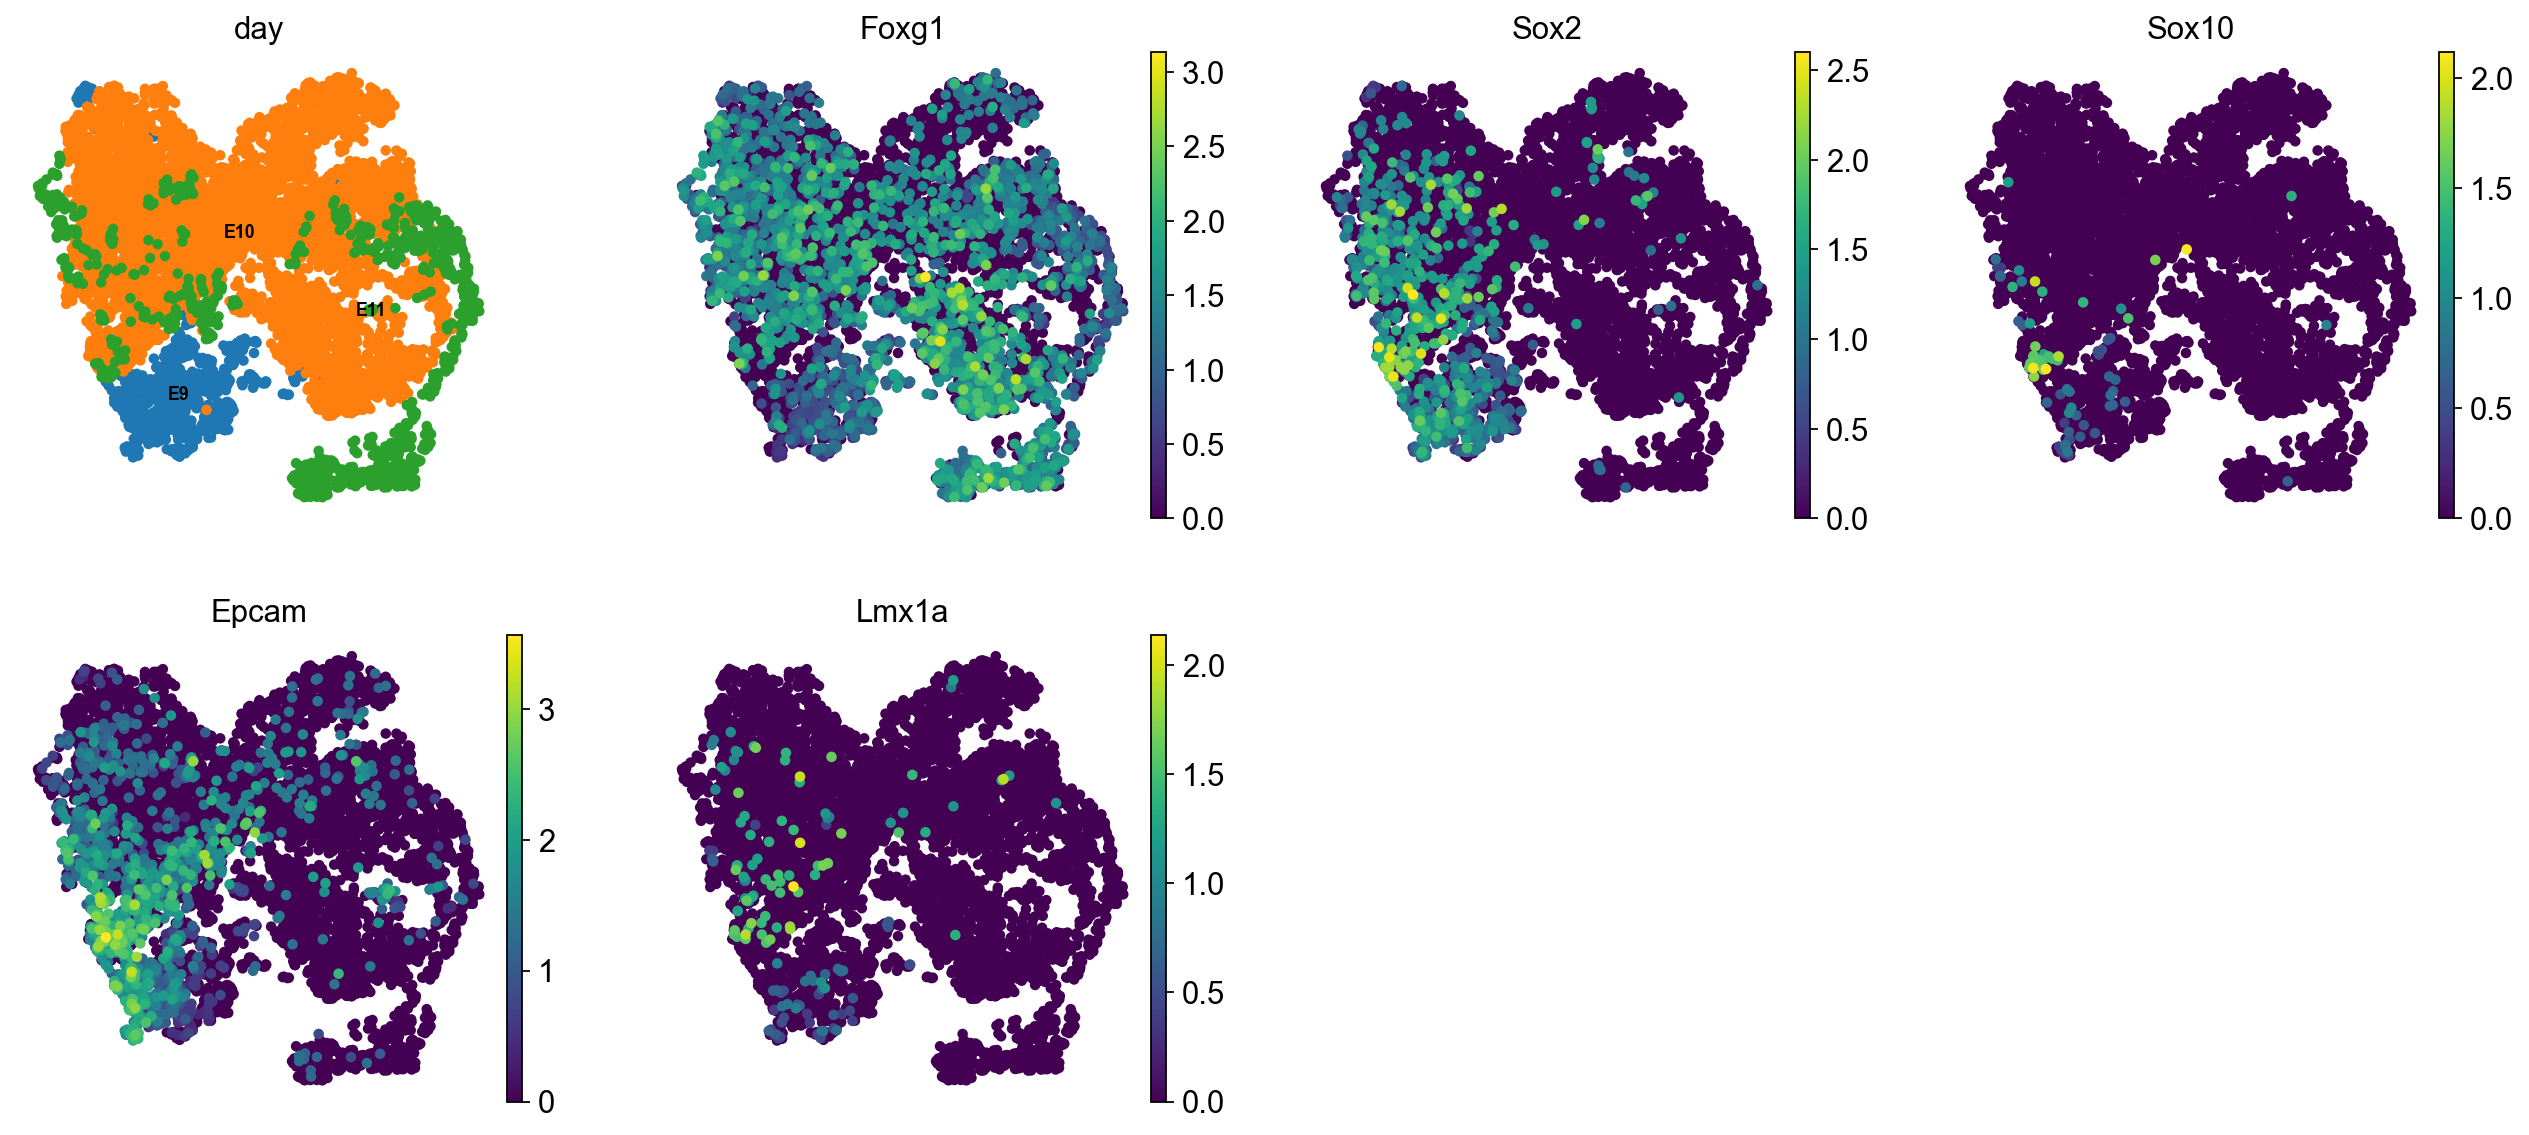

In [29]:
#sc.tl.leiden(adata_genes, resolution=0.5, key_added="leiden_5")
sc.pl.umap(adata_genes, color=["day",  'Foxg1', 'Sox2', 'Sox10', 'Epcam', 'Lmx1a'], frameon=False, legend_loc="on data", size=90)

In [19]:
auc_mtx

,Ahdc1(+),Ak6(+),Arid3a(+),Arntl(+),Ascc1(+),Atf2(+),Atf4(+),Atf5(+),Bach1(+),Bach2(+),...,Zfp882(+),Zfp91(+),Zfp941(+),Zfx(+),Zic1(+),Zic4(+),Zkscan6(+),Zkscan8(+),Zxdb(+),Zxdc(+)
AAAGTCCGTCGTGTTA-1-adata1,0.026135,0.036848,0.033945,0.0,0.048369,0.000000,0.048102,0.015963,0.048788,0.081711,...,0.060497,0.042640,0.037553,0.071960,0.034723,0.000000,0.000000,0.000000,0.000000,0.000000
AAAGTGACATCTCGTC-1-adata1,0.015371,0.029287,0.036621,0.0,0.038575,0.045023,0.050505,0.014153,0.031077,0.086664,...,0.014162,0.025764,0.047628,0.075007,0.053025,0.000487,0.000000,0.056629,0.000000,0.015541
AACAGGGAGACTCTTG-1-adata1,0.005032,0.057454,0.014288,0.0,0.022904,0.000000,0.031601,0.005631,0.018363,0.050153,...,0.000000,0.041460,0.030307,0.036058,0.026629,0.008895,0.000000,0.007435,0.000000,0.000000
AACCTTTCACGTCGGT-1-adata1,0.016203,0.017583,0.036095,0.0,0.033348,0.000000,0.036644,0.003790,0.012848,0.079215,...,0.014560,0.015423,0.027108,0.057198,0.059159,0.000000,0.015489,0.000000,0.000000,0.000000
AACGAAAAGAATGTTG-1-adata1,0.039140,0.027313,0.064915,0.0,0.048541,0.000000,0.076117,0.027176,0.072222,0.115094,...,0.000000,0.021538,0.079403,0.112491,0.064252,0.000000,0.000000,0.000000,0.058447,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGGATGTCATGGCCG-1-adata12,0.030234,0.033354,0.048496,0.0,0.035170,0.013355,0.042126,0.032953,0.053895,0.088369,...,0.005089,0.032351,0.105491,0.069166,0.066172,0.000000,0.077034,0.027096,0.009156,0.034903
TTGGGCGCATGGACAG-1-adata12,0.041355,0.017423,0.033176,0.0,0.033400,0.000000,0.032767,0.017773,0.091535,0.102833,...,0.005045,0.034165,0.153699,0.064717,0.070566,0.053284,0.072078,0.000000,0.009500,0.000000
TTGTTCACACTAGAGG-1-adata12,0.015083,0.025294,0.033382,0.0,0.016885,0.026435,0.034377,0.022566,0.027934,0.080700,...,0.000000,0.028043,0.054026,0.048105,0.043476,0.001992,0.000000,0.035564,0.000000,0.010120
TTGTTTGAGTGCCGAA-1-adata12,0.031148,0.044455,0.051622,0.0,0.027137,0.071802,0.052879,0.049226,0.051527,0.071042,...,0.000000,0.052576,0.102920,0.048483,0.031528,0.000000,0.000000,0.025609,0.062509,0.000000


In [20]:
adata_genes.obs.index = auc_mtx.index

In [21]:
adata=sc.AnnData(auc_mtx,
           obs=adata_genes.obs,uns=adata_genes.uns,obsm=adata_genes.obsm)

/tmp/ipykernel_4014995/4019417087.py:1: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata=sc.AnnData(auc_mtx,


In [22]:
adata

AnnData object with n_obs × n_vars = 7153 × 368
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'

In [23]:
adata.write_h5ad('e_9_10_11_umap_reg.h5ad')

In [25]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scanpy as sc
import numpy as np

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages

# ============================================================
# 1. PAGE SETTINGS — A4 PORTRAIT
# ============================================================

PAGE_W_MM = 210
PAGE_H_MM = 297

PDF_PATH = "E9_10_11_Otic_regulons_TFs_A4_FINAL.pdf"

# ============================================================
# 2. LAYOUT SETTINGS — ADJUST HERE
# ============================================================

# 6 columns × 6 rows = 36 UMAPs per page
NCOLS = 6
N_BLOCKS = 3
NROWS = N_BLOCKS * 2

# 18 regulon–gene pairs per page
REGS_PER_PAGE = NCOLS * N_BLOCKS

# Page margins (mm)
LEFT_MM = 9
RIGHT_MM = 9
TOP_MM = 26
BOTTOM_MM = 23

# Horizontal spacing (mm)
COL_GAP_MM = 3

# Vertical spacing (mm)
PAIR_GAP_MM = 10
BLOCK_GAP_MM = 13

# Page title
PAGE_TITLE = "Otic development — Regulons and TFs"
PAGE_TITLE_SIZE = 11

# UMAP titles
PANEL_TITLE_SIZE = 8
TITLE_PAD = 7

# UMAP points
POINT_SIZE = 30

# Remove incomplete final page
REMOVE_INCOMPLETE_LAST_PAGE = True

# Show a preview of the first page in Jupyter
SHOW_PREVIEW = False

# ============================================================
# 3. FONT / PDF SETTINGS
# ============================================================

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": PANEL_TITLE_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 300,
})

# ============================================================
# 4. COLORMAPS
# ============================================================

regulon_cmap = LinearSegmentedColormap.from_list(
    "regulon",
    ["lightgrey", "green"]
)

gene_cmap = LinearSegmentedColormap.from_list(
    "gene",
    ["lightgrey", "red"]
)

# ============================================================
# 5. SELECT REGULONS
# ============================================================

# Find regulons with corresponding gene expression
regulons_all = [
    r for r in adata.var_names
    if r.replace("(+)", "") in adata_genes.var_names
]

print(f"Original regulons: {len(regulons_all)}")

if REMOVE_INCOMPLETE_LAST_PAGE:

    # Number of complete pages
    N_PAGES = len(regulons_all) // REGS_PER_PAGE

    # Retain only complete pages
    regulons = regulons_all[:N_PAGES * REGS_PER_PAGE]

    removed = regulons_all[len(regulons):]

    print(f"Excluded regulons: {len(removed)}")

    if removed:
        print("Excluded:", removed)

else:
    regulons = regulons_all.copy()

    N_PAGES = int(
        np.ceil(len(regulons) / REGS_PER_PAGE)
    )

print(f"Regulons to plot: {len(regulons)}")
print(f"Pairs per page: {REGS_PER_PAGE}")
print(f"Total PDF pages: {N_PAGES}")

# ============================================================
# 6. CALCULATE PANEL DIMENSIONS
# ============================================================

PANEL_W_MM = (
    PAGE_W_MM
    - LEFT_MM
    - RIGHT_MM
    - (NCOLS - 1) * COL_GAP_MM
) / NCOLS

PANEL_H_MM = (
    PAGE_H_MM
    - TOP_MM
    - BOTTOM_MM
    - N_BLOCKS * PAIR_GAP_MM
    - (N_BLOCKS - 1) * BLOCK_GAP_MM
) / NROWS

# ============================================================
# 7. FUNCTION — PANEL POSITION
# ============================================================

def add_panel(fig, col, block, is_gene=False):

    # Horizontal position
    x_mm = (
        LEFT_MM
        + col * (PANEL_W_MM + COL_GAP_MM)
    )

    # Vertical position
    y_top_mm = (
        TOP_MM
        + block * (
            2 * PANEL_H_MM
            + PAIR_GAP_MM
            + BLOCK_GAP_MM
        )
        + (
            PANEL_H_MM + PAIR_GAP_MM
            if is_gene else 0
        )
    )

    # Convert top coordinate to bottom coordinate
    y_bottom_mm = (
        PAGE_H_MM
        - y_top_mm
        - PANEL_H_MM
    )

    ax = fig.add_axes([
        x_mm / PAGE_W_MM,
        y_bottom_mm / PAGE_H_MM,
        PANEL_W_MM / PAGE_W_MM,
        PANEL_H_MM / PAGE_H_MM
    ])

    return ax

# ============================================================
# 8. GENERATE MULTIPAGE A4 PDF
# ============================================================

with PdfPages(PDF_PATH) as pdf:

    for page in range(N_PAGES):

        start = page * REGS_PER_PAGE

        end = min(
            start + REGS_PER_PAGE,
            len(regulons)
        )

        regs_page = regulons[start:end]

        # ----------------------------------------------------
        # CREATE A4 FIGURE
        # ----------------------------------------------------

        fig = plt.figure(
            figsize=(
                PAGE_W_MM / 25.4,
                PAGE_H_MM / 25.4
            ),
            facecolor="white"
        )

        # ----------------------------------------------------
        # PAGE TITLE
        # ----------------------------------------------------

        fig.text(
            0.5,
            1 - 10 / PAGE_H_MM,
            PAGE_TITLE,
            ha="center",
            va="center",
            fontsize=PAGE_TITLE_SIZE,
            fontweight="bold"
        )

        # ----------------------------------------------------
        # REGULON AND GENE UMAPs
        # ----------------------------------------------------

        for i, reg in enumerate(regs_page):

            gene = reg.replace("(+)", "")

            block = i // NCOLS
            col = i % NCOLS

            # Create axes
            ax_reg = add_panel(
                fig,
                col,
                block,
                is_gene=False
            )

            ax_gene = add_panel(
                fig,
                col,
                block,
                is_gene=True
            )

            # -----------------------------------------------
            # REGULON — GREEN
            # -----------------------------------------------

            sc.pl.umap(
                adata,
                color=reg,
                ax=ax_reg,
                show=False,
                title=f"{reg} regulon",
                cmap=regulon_cmap,
                size=POINT_SIZE,
                frameon=False,
                colorbar_loc=None
            )

            # -----------------------------------------------
            # GENE / TF — RED
            # -----------------------------------------------

            sc.pl.umap(
                adata_genes,
                color=gene,
                ax=ax_gene,
                show=False,
                title=f"{gene} gene",
                cmap=gene_cmap,
                size=POINT_SIZE,
                frameon=False,
                colorbar_loc=None
            )

            # -----------------------------------------------
            # CLEAN AXES
            # -----------------------------------------------

            for ax in (ax_reg, ax_gene):

                ax.set_xlabel("")
                ax.set_ylabel("")

                ax.set_xticks([])
                ax.set_yticks([])

                ax.set_title(
                    ax.get_title(),
                    fontsize=PANEL_TITLE_SIZE,
                    pad=TITLE_PAD
                )

                ax.margins(0.02)

        # ----------------------------------------------------
        # SAVE EXACT A4 PAGE
        # ----------------------------------------------------

        # Do not use bbox_inches="tight"!
        # This preserves the exact 210 × 297 mm page size.

        pdf.savefig(
            fig,
            facecolor="white"
        )

        if SHOW_PREVIEW and page == 0:
            plt.show()

        plt.close(fig)

        print(
            f"Saved page {page + 1}/{N_PAGES}"
        )

# ============================================================
# 9. FINISHED
# ============================================================

print("\n==========================================")
print("PDF successfully generated")
print(f"File: {PDF_PATH}")
print(f"Pages: {N_PAGES}")
print(f"Page size: A4 Portrait (210 × 297 mm)")
print(f"Regulon–gene pairs: {len(regulons)}")
print("==========================================")


Original regulons: 368
Excluded regulons: 8
Excluded: ['Zfp941(+)', 'Zfx(+)', 'Zic1(+)', 'Zic4(+)', 'Zkscan6(+)', 'Zkscan8(+)', 'Zxdb(+)', 'Zxdc(+)']
Regulons to plot: 360
Pairs per page: 18
Total PDF pages: 20
Saved page 1/20
Saved page 2/20
Saved page 3/20
Saved page 4/20
Saved page 5/20
Saved page 6/20
Saved page 7/20
Saved page 8/20
Saved page 9/20
Saved page 10/20
Saved page 11/20
Saved page 12/20
Saved page 13/20
Saved page 14/20
Saved page 15/20
Saved page 16/20
Saved page 17/20
Saved page 18/20
Saved page 19/20
Saved page 20/20

PDF successfully generated
File: E9_10_11_Otic_regulons_TFs_A4_FINAL.pdf
Pages: 20
Page size: A4 Portrait (210 × 297 mm)
Regulon–gene pairs: 360


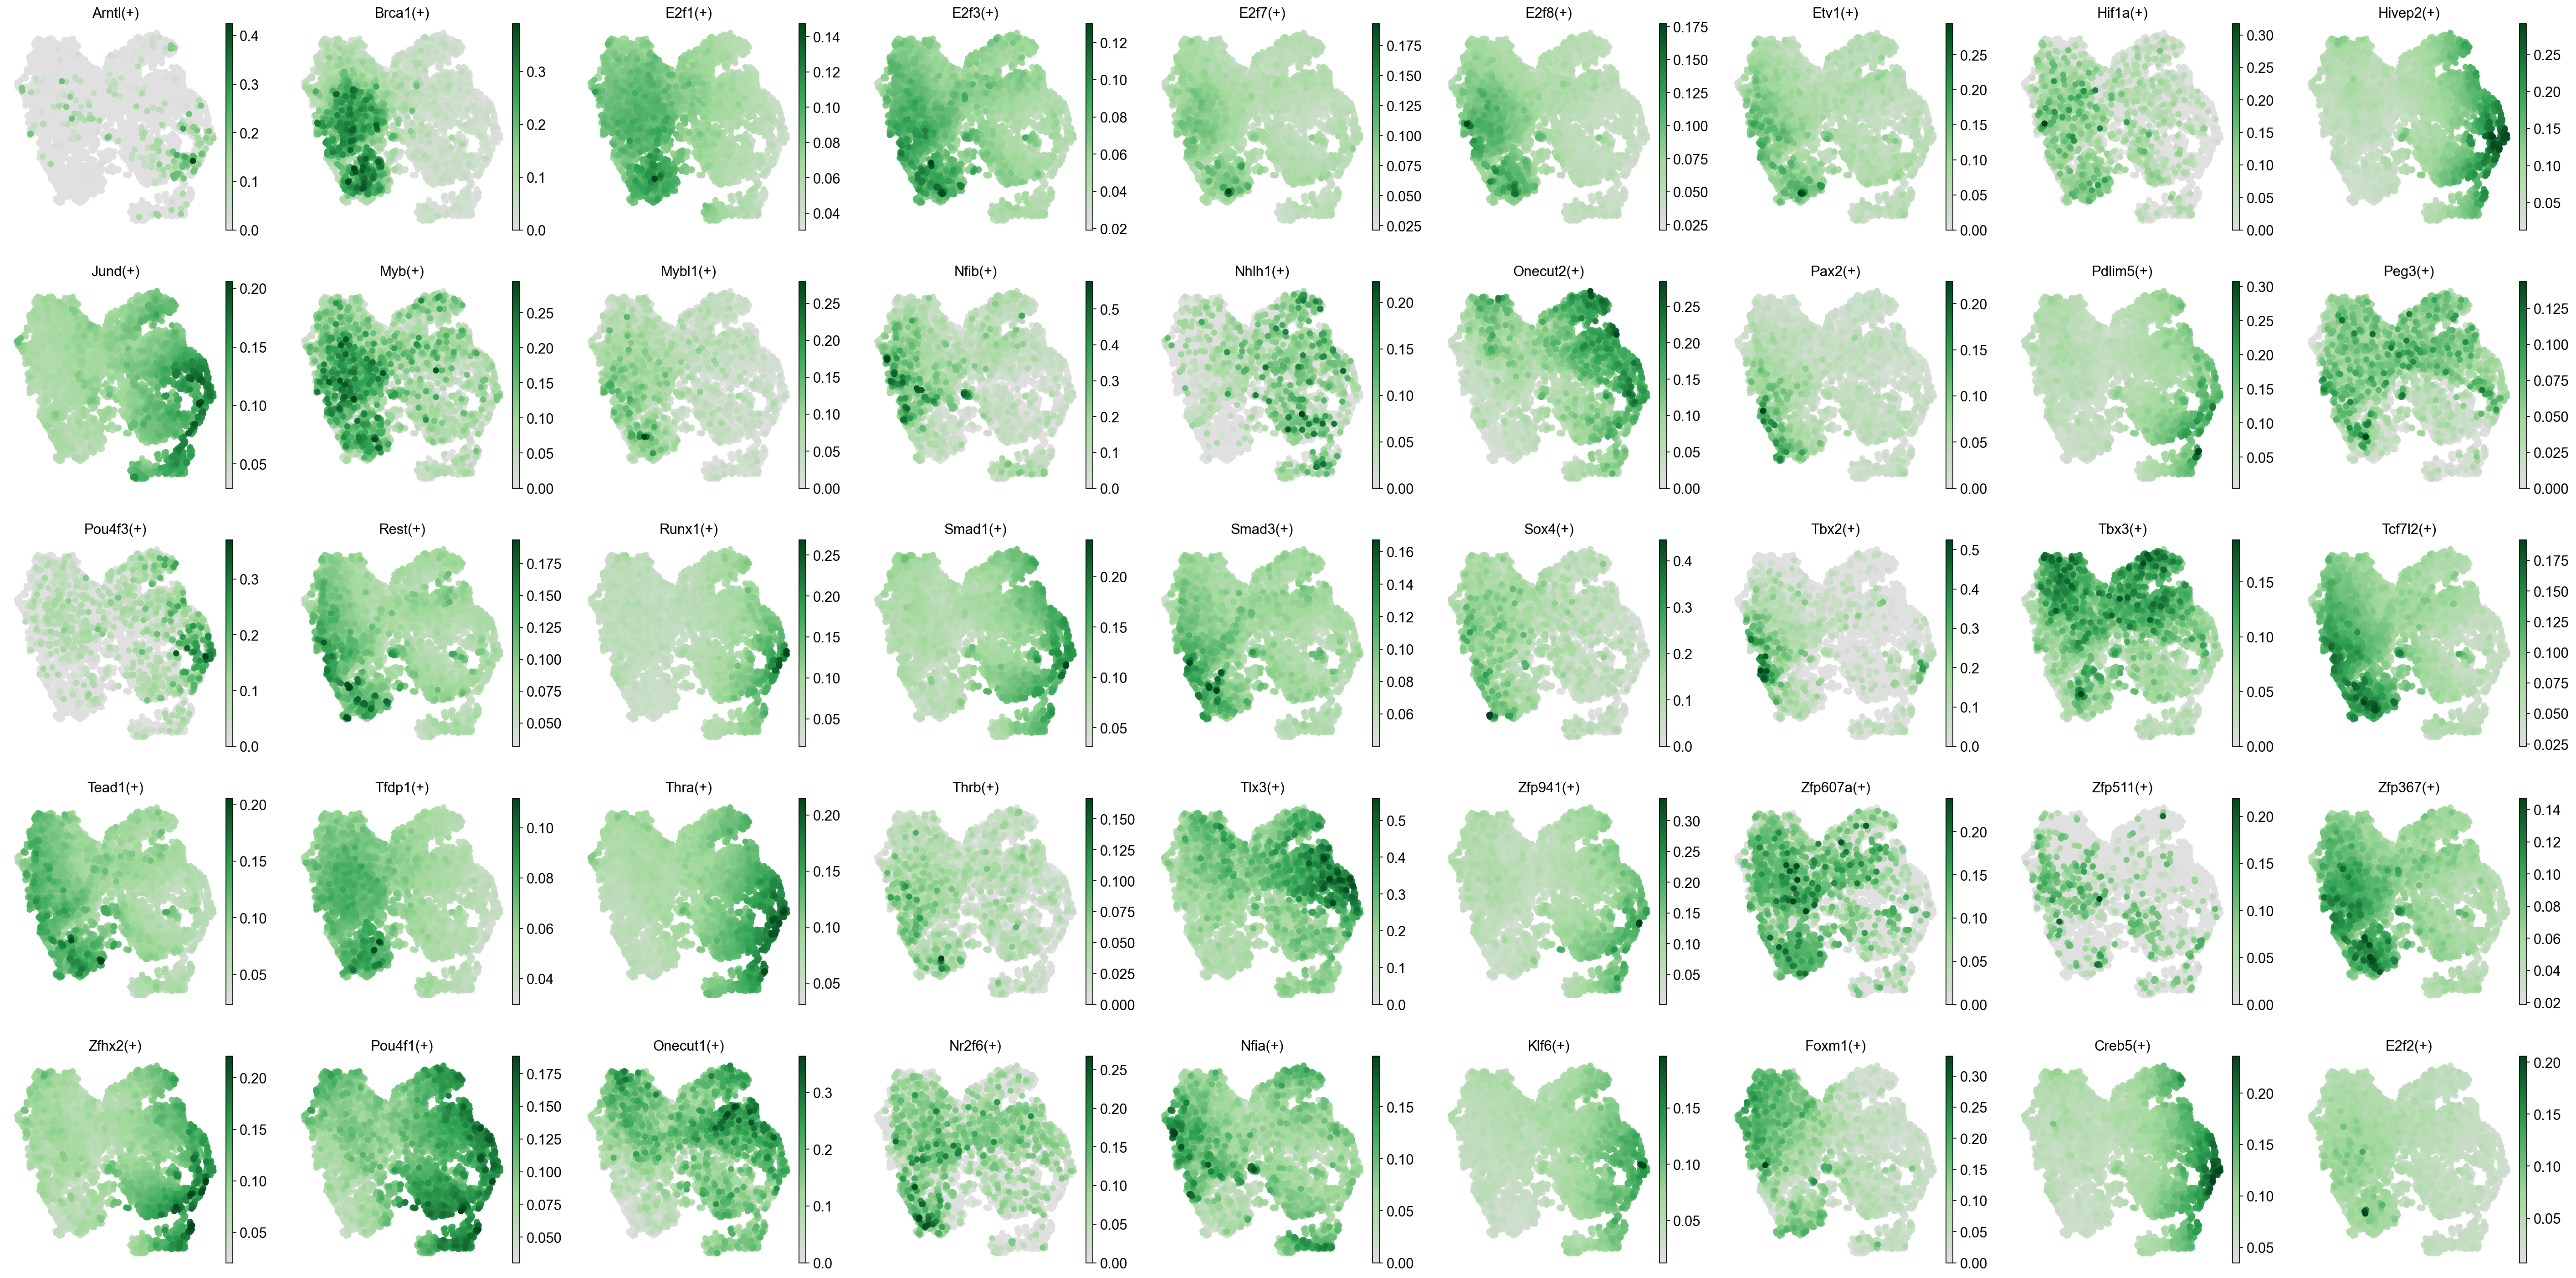

In [22]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

grey_green = LinearSegmentedColormap.from_list(
    "grey_green", ["#e0e0e0", "#a1d99b", "#31a354", "#00441b"]
)

fig = sc.pl.umap(
    adata,
     color=[ 
    "Arntl(+)", "Brca1(+)", "E2f1(+)", "E2f3(+)", "E2f7(+)", "E2f8(+)",
    "Etv1(+)", "Hif1a(+)", "Hivep2(+)", "Jund(+)", "Myb(+)", "Mybl1(+)",
    "Nfib(+)", "Nhlh1(+)", "Onecut2(+)", "Pax2(+)", "Pdlim5(+)", "Peg3(+)",
    "Pou4f3(+)", "Rest(+)", "Runx1(+)", "Smad1(+)", "Smad3(+)", "Sox4(+)",
    "Tbx2(+)", "Tbx3(+)", "Tcf7l2(+)", "Tead1(+)", "Tfdp1(+)", "Thra(+)",
    "Thrb(+)", "Tlx3(+)", "Zfp941(+)", "Zfp607a(+)", "Zfp511(+)",
    "Zfp367(+)", "Zfhx2(+)", "Pou4f1(+)", "Onecut1(+)", "Nr2f6(+)",
    "Nfia(+)", "Klf6(+)",  "Foxm1(+)", "Creb5(+)",
 "E2f2(+)", 
],
        
    ncols=9,
    cmap=grey_green,
   # vmax="p99",
    size=150,
    frameon=False,
    return_fig=True,
    show=False,
)

for ax in fig.axes:                      # rasterize dots for Illustrator
    for coll in ax.collections:
        coll.set_rasterized(True)

fig.savefig("umap_regulons_green.svg", dpi=300, bbox_inches="tight")
plt.show()